In [2]:
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("jena_climate_2009_2016.csv")

print(df.head())
print(f"data shape: {df.shape}")
print(f"column names: {df.columns}")

             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0       1307.75      1.03        

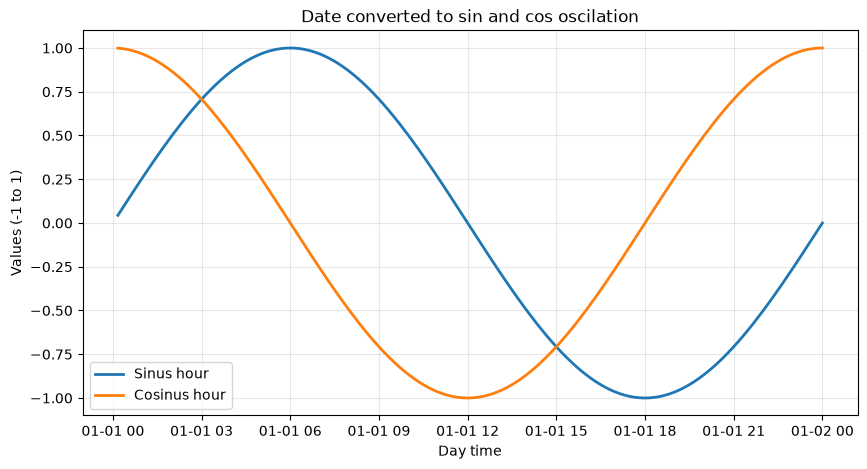

In [4]:
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')

hours_and_minutes = df['Date Time'].dt.hour + (df['Date Time'].dt.minute / 60.0)

df['hour_sin'] = np.sin(hours_and_minutes * (2 * np.pi / 24))
df['hour_cos'] = np.cos(hours_and_minutes * (2 * np.pi / 24))

data_slice = df.iloc[:144]

plt.figure(figsize=(10, 5))
plt.plot(data_slice['Date Time'], data_slice['hour_sin'], label='Sinus hour', linewidth=2)
plt.plot(data_slice['Date Time'], data_slice['hour_cos'], label='Cosinus hour', linewidth=2)
plt.title('Date converted to sin and cos oscilation')
plt.xlabel('Day time')
plt.ylabel('Values (-1 to 1)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

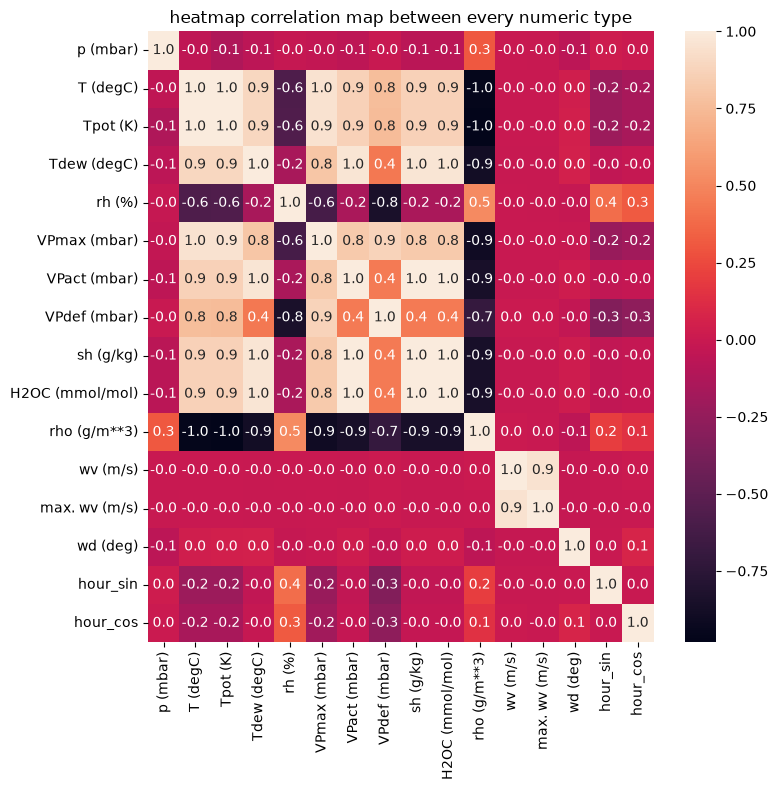

In [5]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(8,8))
plt.title("heatmap correlation map between every numeric type")
sns.heatmap(corr, annot=True, fmt=".1f")
plt.tight_layout()
plt.show()

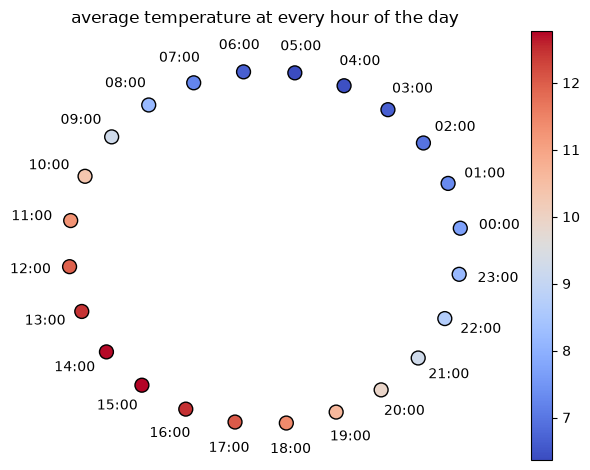

In [6]:
hour = df['Date Time'].dt.hour
hourly_avg = df.groupby(hour).mean(numeric_only=True)

x = 5 * hourly_avg['hour_cos']
y = 5 * hourly_avg['hour_sin']
temp = hourly_avg['T (degC)']

for h in hourly_avg.index:
    text_x = x[h] * 1.20
    text_y = y[h] * 1.15

    label = f"{int(h):02d}:00"

    plt.text(text_x, text_y, label, ha='center', va='center', fontsize=10)

plt.scatter(x, y, c=temp, cmap='coolwarm', s=100, edgecolors='black')
plt.title("average temperature at every hour of the day")
plt.colorbar()
plt.axis('off')

plt.xlim(-6, 6)
plt.ylim(-6, 6.10)

plt.tight_layout()
plt.show()

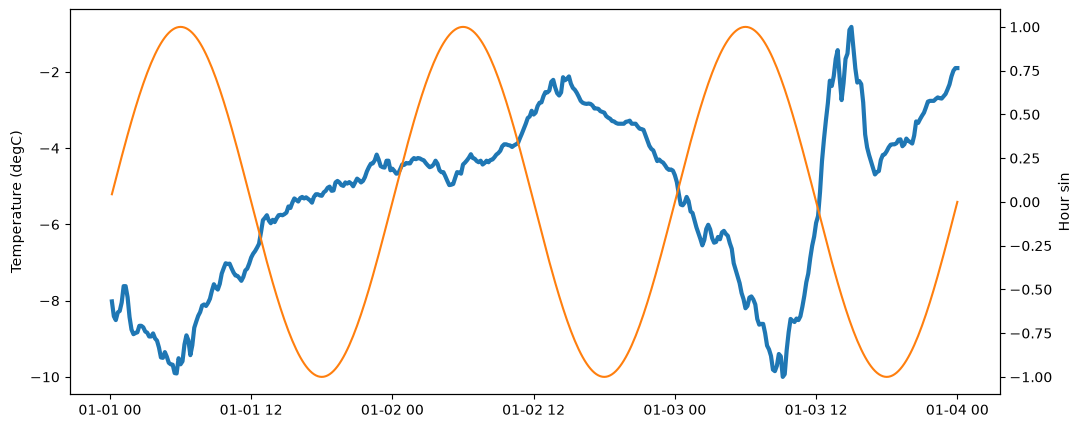

In [7]:
data_slice = df.iloc[:144*3]

fig, ax1 = plt.subplots(figsize=(12,5))

date_time = data_slice['Date Time']
temp_degc = data_slice['T (degC)']
hour_sin = data_slice['hour_sin']

ax1.plot(date_time, temp_degc, color='tab:blue', linewidth=3, label="temperature")
ax2 = ax1.twinx()
ax2.plot(date_time, hour_sin, color='tab:orange', label="hour_sin")
ax1.set_ylabel("Temperature (degC)")
ax2.set_ylabel("Hour sin")
plt.show()

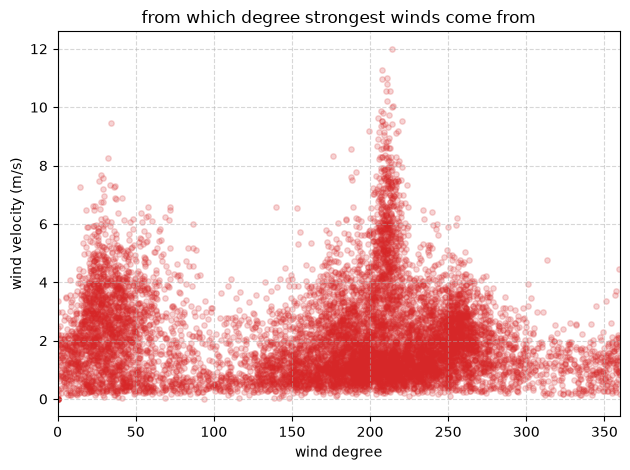

In [8]:
sample_df = df.sample(10000, random_state=42)

wind_deg = sample_df['wd (deg)']
wind_vel = sample_df['wv (m/s)']

plt.scatter(wind_deg, wind_vel, alpha=0.2, color='tab:red', s=15)
plt.title("from which degree strongest winds come from")
plt.xlabel("wind degree")
plt.ylabel("wind velocity (m/s)")

plt.xlim(0, 360)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

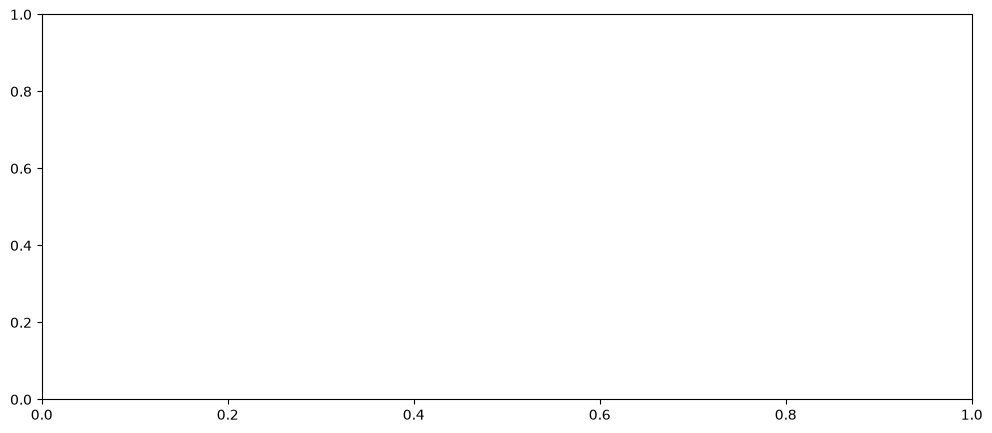

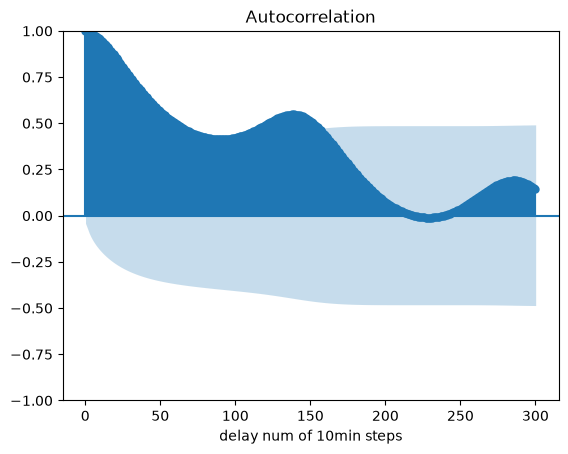

In [9]:
df_temp = df['T (degC)']
df_sample = df_temp.iloc[:2000].dropna()

fig, ax = plt.subplots(figsize=(12,5))
plot_acf(df_sample, lags=300)
plt.xlabel("delay num of 10min steps")
plt.show()

In [11]:
df['Temp_Diff'] = df['T (degC)'].diff()

sorted_temp_diff = df['Temp_Diff'].sort_values(ascending=False)
print(sorted_temp_diff.head(10))

240503    3.18
411267    2.96
40378     2.72
33418     2.40
241391    2.36
241392    2.14
240504    1.99
30286     1.97
209572    1.96
35014     1.96
Name: Temp_Diff, dtype: float64


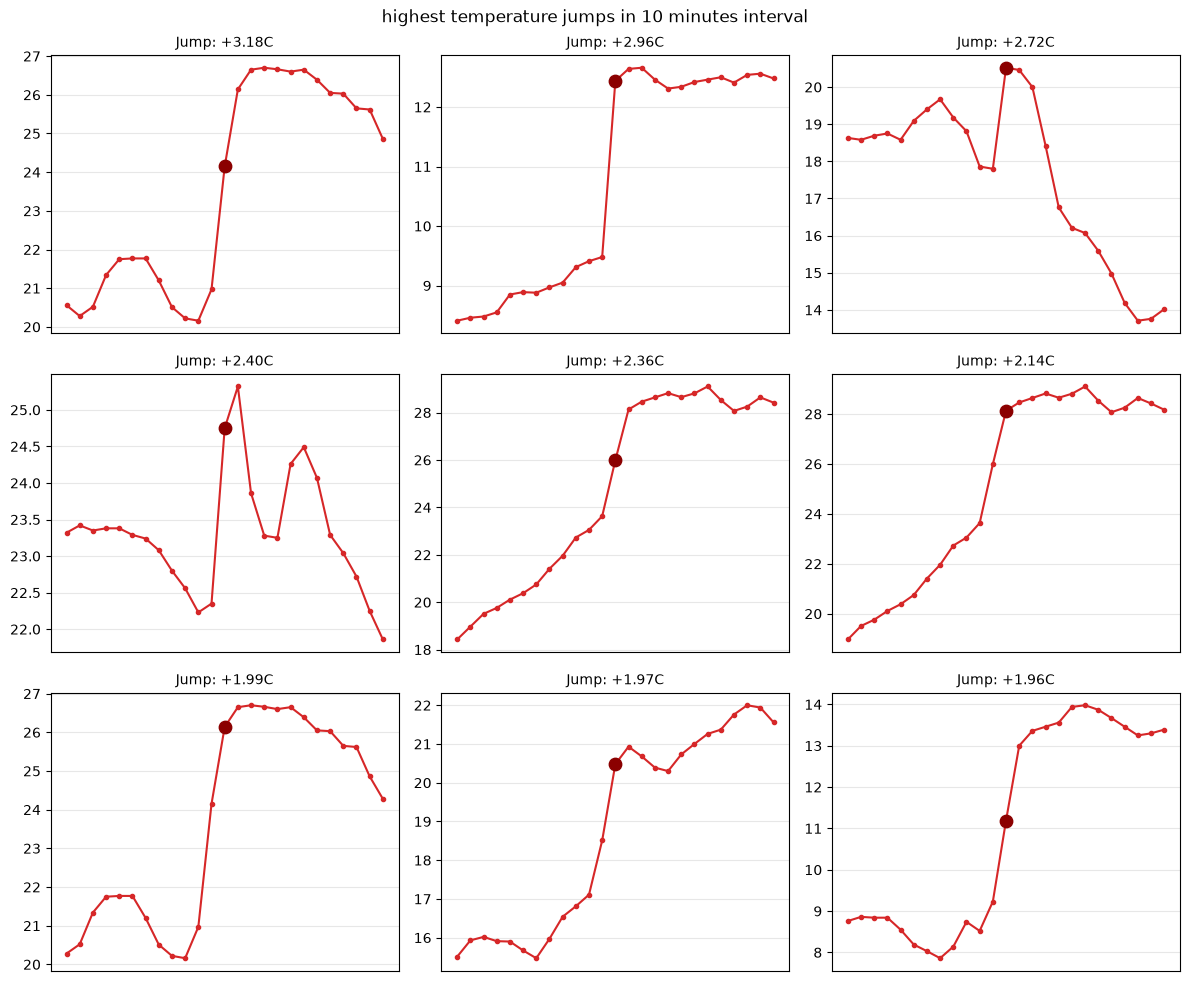

Investigating highest temperature jump: 240503

        T (degC)  wv (m/s)  wd (deg)  p (mbar)  rh (%)
240501     20.16      1.12     118.2    983.12   87.00
240502     20.97      1.17      52.7    983.58   80.40
240503     24.15      1.68     239.3    983.83   61.70
240504     26.14      3.44     246.6    984.06   55.18
240505     26.65      3.48     255.6    984.13   53.29


In [29]:
fig, axes = plt.subplots(3,3, figsize=(12, 10))
axes = axes.flatten()

for i, (idx, temp_diff) in enumerate(sorted_temp_diff.head(9).items()):
    ax1 = axes[i]

    pos = df.index.get_loc(idx)

    window = df.iloc[pos - 12 : pos + 13]

    ax1.plot(range(len(window)), window['T (degC)'], color='tab:red', marker='.')
    ax1.scatter(12, window['T (degC)'].iloc[12], color='darkred', s=80, zorder=5)

    ax1.set_title(f"Jump: +{temp_diff:.2f}C", fontsize=10)
    ax1.grid(True, alpha=0.3)

    ax1.set_xticks([])

fig.suptitle("highest temperature jumps in 10 minutes interval")
plt.tight_layout()
plt.show()

top_idx = sorted_temp_diff.index[0]
pos = df.index.get_loc(top_idx)

investigate_columns = ['T (degC)', 'wv (m/s)', 'wd (deg)', 'p (mbar)', 'rh (%)']

print(f"Investigating highest temperature jump: {top_idx}\n")
print(df[investigate_columns].iloc[pos-2 : pos+3])